## 1. Install Dependencies & Hugging Face Login

In [1]:
!pip install -q bert-score tokenizers

import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.0 MB/s eta 0:00:00


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CUDA available: True
GPU count: 2
GPU: Tesla T4
VRAM: 15.6 GB
Using device: cuda


## 3. Configuration

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import numpy as np
from dataclasses import dataclass
from tqdm.auto import tqdm

# === Reproducibility ===
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# === Dataset ===
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
# Source mixing weights (for target steady-state distribution)
SOURCE_WEIGHTS = {
    "train_supreme_court.json": 0.40,
    "train_high_courts.json": 0.30,
    "train_acts.json": 0.15,
    "train_tribunals.json": 0.15,
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# === Model Architecture ===
VOCAB_SIZE = 32000  # Custom BPE tokenizer vocab size (set here, confirmed after training)
D_MODEL = 768
N_LAYERS = 12
N_HEADS = 12
HEAD_DIM = D_MODEL // N_HEADS  # 64
D_FF = 2048  # SwiGLU intermediate size
MAX_SEQ_LEN = 1024
ROPE_BASE = 10000.0
DROPOUT = 0.0

# === Training ===
TOTAL_TOKENS = 200_000_000       # 500M tokens total target
BLOCK_SIZE = 1024                 # context/sequence length for training
BATCH_SIZE = 16                   # micro batch size (sequences per step)
GRADIENT_ACCUMULATION_STEPS = 4   # effective batch = 16 * 4 = 64 sequences = 65536 tokens
PEAK_LR = 6e-4
MIN_LR = 6e-6
WARMUP_STEPS = 300
WEIGHT_DECAY = 0.1
BETA1 = 0.9
BETA2 = 0.95
GRAD_CLIP = 1.0
# WSD schedule: warmup 2000 steps, stable phase, decay last 10% of total steps

# === PAS (Plasticity-Adjusted Sampling) ===
PAS_LAMBDA = 5.0
# Bucket definitions by word count
PAS_BUCKET_THRESHOLDS = [3000, 8000]  # [easy <= 3000, medium 3000-8000, hard > 8000]
PAS_TARGET_WEIGHTS = [0.20, 0.40, 0.40]  # [easy, medium, hard] steady-state

# === Validation ===
VAL_TOKENS = 5_000_000  # 5M tokens for validation
VAL_INTERVAL_STEPS = 500  # evaluate every N steps
VAL_FRACTION = 0.03  # fraction of documents reserved for validation

# === Generation ===
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7
TOP_P = 0.9
TOP_K = 50
REPETITION_PENALTY = 1.1

# === Checkpointing ===
SAVE_INTERVAL_STEPS = 2000
SAVE_TOTAL_LIMIT = 3  # keep only last N checkpoints to save disk

# === Tokenizer Training ===
TOKENIZER_VOCAB_SIZE = 32000     # BPE vocabulary size
TOKENIZER_MIN_FREQ = 2           # minimum frequency for a token to be included
TOKENIZER_SAMPLE_SIZE = 200_000  # number of documents to sample for tokenizer training (for speed)
TOKENIZER_DIR = "/kaggle/working/legal_tokenizer"

# === Output Paths ===
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-lm-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
os.makedirs(TOKENIZER_DIR, exist_ok=True)

print("Configuration loaded.")
print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS} sequences")
print(f"Tokens per effective batch: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE:,}")

Configuration loaded.
Effective batch size: 64 sequences
Tokens per effective batch: 65,536


In [4]:
# TOTAL_TOKENS = 1_000_000
# BATCH_SIZE = 2
# GRADIENT_ACCUMULATION_STEPS = 4

# WARMUP_STEPS = 20

# VAL_TOKENS = 100_000
# VAL_INTERVAL_STEPS = 50

# SAVE_INTERVAL_STEPS = 100

# TOKENIZER_SAMPLE_SIZE = 10_000

In [5]:
import os
import numpy as np
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

# 1. Base path for the uploaded Kaggle dataset
DATASET_PATH = "/kaggle/input/datasets/vivekchandwani7/m1-200m-dataset"

# The folders match the structure shown in image_b69a83.png
CS781_DIR = os.path.join(DATASET_PATH, "cs781_phase1")
TOKENIZER_DIR = os.path.join(DATASET_PATH, "legal_tokenizer")

# 2. Load the trained tokenizer directly from the dataset
print(f"Loading tokenizer from {TOKENIZER_DIR}...")
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOKENIZER_DIR)
VOCAB_SIZE = len(tokenizer)
print(f"Tokenizer loaded. VOCAB_SIZE updated to: {VOCAB_SIZE}")

# 3. Define paths to the pre-processed bucket binary files
BUCKET_BIN_PATHS = {
    0: os.path.join(CS781_DIR, "bucket_0.bin"),
    1: os.path.join(CS781_DIR, "bucket_1.bin"),
    2: os.path.join(CS781_DIR, "bucket_2.bin"),
}

# Verify the bucket files exist
for b, path in BUCKET_BIN_PATHS.items():
    assert os.path.exists(path), f"Missing {path}"

# 4. Load and process validation data into 'val_blocks'
VAL_BIN_PATH = os.path.join(CS781_DIR, "val.bin")
print(f"Loading validation tokens from {VAL_BIN_PATH}...")

# Load via memory map to avoid RAM overhead
val_tokens_mmap = np.memmap(VAL_BIN_PATH, dtype=np.uint32, mode='r')

# Trim tokens to fit perfectly into uniform blocks
total_val_length = (len(val_tokens_mmap) // BLOCK_SIZE) * BLOCK_SIZE
val_tokens_trimmed = val_tokens_mmap[:total_val_length]

# Reshape into lists of blocks required by the evaluate_val function
val_blocks = val_tokens_trimmed.reshape(-1, BLOCK_SIZE).astype(np.int64).tolist()
print(f"Validation blocks prepared: {len(val_blocks)} blocks of size {BLOCK_SIZE}.")

# 5. Download ONLY the test file (needed for Generation later)
print("Downloading test.json from Hugging Face...")
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN,
)
print(f"Test file ready: {test_file_path}")

Loading tokenizer from /kaggle/input/datasets/vivekchandwani7/m1-200m-dataset/legal_tokenizer...
Tokenizer loaded. VOCAB_SIZE updated to: 32000
Loading validation tokens from /kaggle/input/datasets/vivekchandwani7/m1-200m-dataset/cs781_phase1/val.bin...
Validation blocks prepared: 4885 blocks of size 1024.


test.json: 0.00B [00:00, ?B/s]

Test file ready: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 4. Download Training & Test Data

In [6]:
# from huggingface_hub import hf_hub_download

# train_file_paths = {}
# for tf in TRAIN_FILES:
#     path = hf_hub_download(
#         repo_id=HF_DATASET_REPO,
#         filename=tf,
#         repo_type="dataset",
#         token=HF_TOKEN,
#     )
#     source_name = os.path.basename(tf)
#     train_file_paths[source_name] = path
#     print(f"Downloaded {source_name}: {path}")

# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO,
#     filename=TEST_FILE,
#     repo_type="dataset",
#     token=HF_TOKEN,
# )
# print(f"\nTest file: {test_file_path}")

## 5. Train BPE Tokenizer on Legal Corpus

In [7]:
pip install ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 2.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [8]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
from transformers import PreTrainedTokenizerFast
import tempfile
import ijson
import random
import gc
import os
from tqdm.auto import tqdm

# # --- Step 1: Collect training texts for tokenizer (Memory Efficient & Weighted) ---
# print("Collecting texts for tokenizer training via weighted streaming...")

# # Calculate how many documents we need from each file
# tokenizer_quotas = {k: int(TOKENIZER_SAMPLE_SIZE * v) for k, v in SOURCE_WEIGHTS.items()}
# tokenizer_texts = []
# total_docs_seen_global = 0
# random.seed(SEED)

# for source_name, fpath in train_file_paths.items():
#     target_sample_size = tokenizer_quotas.get(source_name, 0)
#     print(f"\nTarget sample for {source_name}: {target_sample_size} docs")
    
#     file_sampled_texts = []
#     docs_seen_in_file = 0
    
#     with open(fpath, "rb") as f:
#         # ijson streams the data instead of loading it entirely into RAM
#         records = ijson.items(f, "item")
        
#         # tqdm progress bar (acts as a dynamic counter since we don't know total docs upfront)
#         with tqdm(desc=f"Streaming {source_name}", unit=" docs") as pbar:
#             for rec in records:
#                 text = rec["text"]
                
#                 # Reservoir Sampling: Maintains a random sample of fixed size per file
#                 if docs_seen_in_file < target_sample_size:
#                     file_sampled_texts.append(text)
#                 else:
#                     j = random.randint(0, docs_seen_in_file)
#                     if j < target_sample_size:
#                         file_sampled_texts[j] = text
                        
#                 docs_seen_in_file += 1
#                 total_docs_seen_global += 1
#                 pbar.update(1)

#     print(f"-> Extracted {len(file_sampled_texts)} docs from {docs_seen_in_file} total docs.")
#     tokenizer_texts.extend(file_sampled_texts)

# print(f"\nTotal documents available in corpus: {total_docs_seen_global}")
# print(f"Total sampled documents for tokenizer training: {len(tokenizer_texts)}")

# # --- Step 2: Write texts to a temporary file (tokenizers library reads from files) ---
# tokenizer_train_file = os.path.join(TOKENIZER_DIR, "tokenizer_train_corpus.txt")
# print(f"\nWriting tokenizer training corpus to {tokenizer_train_file}...")
# with open(tokenizer_train_file, "w", encoding="utf-8") as f:
#     for text in tqdm(tokenizer_texts, desc="Writing corpus"):
#         # Write each document as a single line (replace newlines with spaces)
#         clean_text = text.replace("\n", " ").replace("\r", " ").strip()
#         if clean_text:  # skip empty docs
#             f.write(clean_text + "\n")

# del tokenizer_texts  # free memory
# gc.collect()

# # --- Step 3: Train BPE tokenizer ---
# print(f"\nTraining BPE tokenizer (vocab_size={TOKENIZER_VOCAB_SIZE})...")

# # Define special tokens
# SPECIAL_TOKENS = ["<|pad|>", "<|eos|>", "<|bos|>", "<|unk|>"]

# # Create a Byte-Level BPE tokenizer
# tok = Tokenizer(models.BPE(unk_token="<|unk|>"))

# # Pre-tokenization: ByteLevel splits into bytes, handles all Unicode
# # add_prefix_space=False so we don't add a space before first token
# tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)

# # Decoder: ByteLevel to reconstruct text from tokens
# tok.decoder = decoders.ByteLevel()

# # Post-processor: ByteLevel to handle offsets correctly
# tok.post_processor = processors.ByteLevel(trim_offsets=True)

# # Trainer configuration
# trainer = trainers.BpeTrainer(
#     vocab_size=TOKENIZER_VOCAB_SIZE,
#     min_frequency=TOKENIZER_MIN_FREQ,
#     special_tokens=SPECIAL_TOKENS,
#     show_progress=True,
#     initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
# )

# # Train!
# tok.train(files=[tokenizer_train_file], trainer=trainer)

# print(f"Tokenizer trained! Vocab size: {tok.get_vocab_size()}")

# # --- Step 4: Save the raw tokenizer ---
# raw_tokenizer_path = os.path.join(TOKENIZER_DIR, "tokenizer.json")
# tok.save(raw_tokenizer_path)

# # --- Step 5: Wrap into a HuggingFace PreTrainedTokenizerFast ---
# tokenizer = PreTrainedTokenizerFast(
#     tokenizer_object=tok,
#     unk_token="<|unk|>",
#     eos_token="<|eos|>",
#     bos_token="<|bos|>",
#     pad_token="<|pad|>",
# )

# # Save in HuggingFace format for later loading
# tokenizer.save_pretrained(TOKENIZER_DIR)
# print(f"Tokenizer saved to: {TOKENIZER_DIR}")

# # --- Step 6: Verify and update VOCAB_SIZE ---
# actual_vocab_size = len(tokenizer)
# print(f"\nActual vocab size: {actual_vocab_size}")
# print(f"EOS token: '{tokenizer.eos_token}' (id={tokenizer.eos_token_id})")
# print(f"BOS token: '{tokenizer.bos_token}' (id={tokenizer.bos_token_id})")
# print(f"PAD token: '{tokenizer.pad_token}' (id={tokenizer.pad_token_id})")
# print(f"UNK token: '{tokenizer.unk_token}' (id={tokenizer.unk_token_id})")

# # Update VOCAB_SIZE to actual value
# VOCAB_SIZE = actual_vocab_size
# print(f"\nVOCAB_SIZE updated to: {VOCAB_SIZE}")

# # --- Step 7: Quick quality check ---
# test_sentences = [
#     "The appellant herein is the original plaintiff in the suit.",
#     "Section 302 of the Indian Penal Code, 1860, deals with punishment for murder.",
#     "The learned counsel for the respondent submitted that the High Court erred in its judgment.",
#     "REPORTABLE IN THE SUPREME COURT OF INDIA CIVIL APPELLATE JURISDICTION",
#     "Notwithstanding anything contained in sub-section (1), the Central Government may",
# ]

# print("\n--- Tokenizer Quality Check ---")
# for sent in test_sentences:
#     tokens = tokenizer.encode(sent, add_special_tokens=False)
#     decoded = tokenizer.decode(tokens)
#     token_strs = tokenizer.convert_ids_to_tokens(tokens)
#     ratio = len(sent.split()) / len(tokens)  # words per token (higher = more efficient)
#     print(f"  [{len(tokens):3d} tok, {ratio:.2f} w/t] {sent[:80]}...")
#     print(f"    Tokens: {token_strs[:15]}{'...' if len(token_strs) > 15 else ''}")
#     # Verify round-trip
#     assert decoded.strip() == sent.strip(), f"Round-trip failed: '{decoded}' != '{sent}'"

# print("\nAll round-trip checks passed!")

# # Clean up temp file
# if os.path.exists(tokenizer_train_file):
#     os.remove(tokenizer_train_file)
#     print(f"Cleaned up {tokenizer_train_file}")

In [9]:
import random
import ijson
import numpy as np
import os
from tqdm.auto import tqdm

# # ------------------------------------------------------------------
# # Configuration & Quotas
# # ------------------------------------------------------------------
# TRAIN_BIN = "train_tokens.bin"
# VAL_BIN = "val_tokens.bin"

# random.seed(SEED)

# # Calculate exact token targets per file based on your SOURCE_WEIGHTS
# train_quotas = {k: int(TOTAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}
# val_quotas = {k: int(VAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}

# # ------------------------------------------------------------------
# # Create disk-backed token arrays (Write Mode)
# # ------------------------------------------------------------------
# train_tokens = np.memmap(
#     TRAIN_BIN,
#     dtype=np.uint32,
#     mode="w+",
#     shape=(TOTAL_TOKENS,)
# )

# val_tokens = np.memmap(
#     VAL_BIN,
#     dtype=np.uint32,
#     mode="w+",
#     shape=(VAL_TOKENS,)
# )

# # Global positions in the memmap arrays
# global_train_pos = 0
# global_val_pos = 0

# total_target = TOTAL_TOKENS + VAL_TOKENS

# # ------------------------------------------------------------------
# # Stream JSON and tokenize per-file
# # ------------------------------------------------------------------
# print(f"Targeting {TOTAL_TOKENS:,} Train Tokens and {VAL_TOKENS:,} Validation Tokens.")

# # Single global progress bar for all tokens collected
# with tqdm(total=total_target, desc="Collecting tokens globally", unit="tok", unit_scale=True) as pbar:
    
#     for source_name, fpath in train_file_paths.items():
#         target_train = train_quotas.get(source_name, 0)
#         target_val = val_quotas.get(source_name, 0)
        
#         source_train_pos = 0
#         source_val_pos = 0
        
#         with open(fpath, "rb") as f:
#             records = ijson.items(f, "item")
            
#             for data in records:
#                 text = data["text"]
#                 tokens = tokenizer.encode(text, add_special_tokens=False)
                
#                 # Use VAL_FRACTION from your config to route to validation/train sets
#                 if random.random() < VAL_FRACTION:
#                     if source_val_pos < target_val:
#                         remaining = target_val - source_val_pos
#                         chunk = tokens[:remaining]
                        
#                         val_tokens[global_val_pos : global_val_pos + len(chunk)] = chunk
                        
#                         source_val_pos += len(chunk)
#                         global_val_pos += len(chunk)
#                         pbar.update(len(chunk))  # Update global tqdm
#                 else:
#                     if source_train_pos < target_train:
#                         remaining = target_train - source_train_pos
#                         chunk = tokens[:remaining]
                        
#                         train_tokens[global_train_pos : global_train_pos + len(chunk)] = chunk
                        
#                         source_train_pos += len(chunk)
#                         global_train_pos += len(chunk)
#                         pbar.update(len(chunk))  # Update global tqdm
                
#                 # Move to the next file if this file's quota is fully met
#                 if source_train_pos >= target_train and source_val_pos >= target_val:
#                     break

# # ------------------------------------------------------------------
# # Flush memmaps
# # ------------------------------------------------------------------
# train_tokens.flush()
# val_tokens.flush()

# # ------------------------------------------------------------------
# # Final stats
# # ------------------------------------------------------------------
# print(f"\nTrain tokens total:      {global_train_pos:,} / {TOTAL_TOKENS:,}")
# print(f"Validation tokens total: {global_val_pos:,} / {VAL_TOKENS:,}")

# print(f"Train file size:         {global_train_pos * 4 / 1024**3:.2f} GB")
# print(f"Validation file size:    {global_val_pos * 4 / 1024**3:.2f} GB")
# print(f"Saved train tokens to:   {TRAIN_BIN}")
# print(f"Saved val tokens to:     {VAL_BIN}")

# # ------------------------------------------------------------------
# # Re-open in read-only mode for training
# # ------------------------------------------------------------------
# train_tokens = np.memmap(
#     TRAIN_BIN,
#     dtype=np.uint32,
#     mode="r",
#     shape=(TOTAL_TOKENS,)
# )

# val_tokens = np.memmap(
#     VAL_BIN,
#     dtype=np.uint32,
#     mode="r",
#     shape=(VAL_TOKENS,)
# )

In [10]:
# from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
# from transformers import PreTrainedTokenizerFast
# import tempfile

# # --- Step 1: Collect training texts for tokenizer ---
# print("Collecting texts for tokenizer training...")
# tokenizer_texts = []

# for source_name, fpath in train_file_paths.items():
#     with open(fpath, "r", encoding="utf-8") as f:
#         records = json.load(f)
#     for rec in records:
#         tokenizer_texts.append(rec["text"])
#     print(f"  {source_name}: {len(records)} docs")
#     del records

# print(f"Total documents available: {len(tokenizer_texts)}")

# # Sample for speed if corpus is very large
# random.seed(SEED)
# if len(tokenizer_texts) > TOKENIZER_SAMPLE_SIZE:
#     tokenizer_texts = random.sample(tokenizer_texts, TOKENIZER_SAMPLE_SIZE)
#     print(f"Sampled {TOKENIZER_SAMPLE_SIZE} documents for tokenizer training")

# # --- Step 2: Write texts to a temporary file (tokenizers library reads from files) ---
# tokenizer_train_file = os.path.join(TOKENIZER_DIR, "tokenizer_train_corpus.txt")
# print(f"Writing tokenizer training corpus to {tokenizer_train_file}...")
# with open(tokenizer_train_file, "w", encoding="utf-8") as f:
#     for text in tqdm(tokenizer_texts, desc="Writing corpus"):
#         # Write each document as a single line (replace newlines with spaces)
#         clean_text = text.replace("\n", " ").replace("\r", " ").strip()
#         if clean_text:  # skip empty docs
#             f.write(clean_text + "\n")

# del tokenizer_texts  # free memory
# import gc; gc.collect()

# # --- Step 3: Train BPE tokenizer ---
# print(f"\nTraining BPE tokenizer (vocab_size={TOKENIZER_VOCAB_SIZE})...")

# # Define special tokens
# SPECIAL_TOKENS = ["<|pad|>", "<|eos|>", "<|bos|>", "<|unk|>"]

# # Create a Byte-Level BPE tokenizer
# tok = Tokenizer(models.BPE(unk_token="<|unk|>"))

# # Pre-tokenization: ByteLevel splits into bytes, handles all Unicode
# # add_prefix_space=False so we don't add a space before first token
# tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)

# # Decoder: ByteLevel to reconstruct text from tokens
# tok.decoder = decoders.ByteLevel()

# # Post-processor: ByteLevel to handle offsets correctly
# tok.post_processor = processors.ByteLevel(trim_offsets=True)

# # Trainer configuration
# trainer = trainers.BpeTrainer(
#     vocab_size=TOKENIZER_VOCAB_SIZE,
#     min_frequency=TOKENIZER_MIN_FREQ,
#     special_tokens=SPECIAL_TOKENS,
#     show_progress=True,
#     initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
# )

# # Train!
# tok.train(files=[tokenizer_train_file], trainer=trainer)

# print(f"Tokenizer trained! Vocab size: {tok.get_vocab_size()}")

# # --- Step 4: Save the raw tokenizer ---
# raw_tokenizer_path = os.path.join(TOKENIZER_DIR, "tokenizer.json")
# tok.save(raw_tokenizer_path)

# # --- Step 5: Wrap into a HuggingFace PreTrainedTokenizerFast ---
# tokenizer = PreTrainedTokenizerFast(
#     tokenizer_object=tok,
#     unk_token="<|unk|>",
#     eos_token="<|eos|>",
#     bos_token="<|bos|>",
#     pad_token="<|pad|>",
# )

# # Save in HuggingFace format for later loading
# tokenizer.save_pretrained(TOKENIZER_DIR)
# print(f"Tokenizer saved to: {TOKENIZER_DIR}")

# # --- Step 6: Verify and update VOCAB_SIZE ---
# actual_vocab_size = len(tokenizer)
# print(f"\nActual vocab size: {actual_vocab_size}")
# print(f"EOS token: '{tokenizer.eos_token}' (id={tokenizer.eos_token_id})")
# print(f"BOS token: '{tokenizer.bos_token}' (id={tokenizer.bos_token_id})")
# print(f"PAD token: '{tokenizer.pad_token}' (id={tokenizer.pad_token_id})")
# print(f"UNK token: '{tokenizer.unk_token}' (id={tokenizer.unk_token_id})")

# # Update VOCAB_SIZE to actual value
# VOCAB_SIZE = actual_vocab_size
# print(f"\nVOCAB_SIZE updated to: {VOCAB_SIZE}")

# # --- Step 7: Quick quality check ---
# test_sentences = [
#     "The appellant herein is the original plaintiff in the suit.",
#     "Section 302 of the Indian Penal Code, 1860, deals with punishment for murder.",
#     "The learned counsel for the respondent submitted that the High Court erred in its judgment.",
#     "REPORTABLE IN THE SUPREME COURT OF INDIA CIVIL APPELLATE JURISDICTION",
#     "Notwithstanding anything contained in sub-section (1), the Central Government may",
# ]

# print("\n--- Tokenizer Quality Check ---")
# for sent in test_sentences:
#     tokens = tokenizer.encode(sent, add_special_tokens=False)
#     decoded = tokenizer.decode(tokens)
#     token_strs = tokenizer.convert_ids_to_tokens(tokens)
#     ratio = len(sent.split()) / len(tokens)  # words per token (higher = more efficient)
#     print(f"  [{len(tokens):3d} tok, {ratio:.2f} w/t] {sent[:80]}...")
#     print(f"    Tokens: {token_strs[:15]}{'...' if len(token_strs) > 15 else ''}")
#     # Verify round-trip
#     assert decoded.strip() == sent.strip(), f"Round-trip failed: '{decoded}' != '{sent}'"

# print("\nAll round-trip checks passed!")

# # Clean up temp file
# if os.path.exists(tokenizer_train_file):
#     os.remove(tokenizer_train_file)
#     print(f"Cleaned up {tokenizer_train_file}")

## 6. Load, Tag, and Bucket Training Documents

In [11]:
import gc
import json
import random
import ijson
import os
from tqdm.auto import tqdm

# # --- Step 6: Load, Tag, and Bucket Training Documents (Disk-Backed) ---
# print("Streaming documents, assigning buckets, and writing to disk...")

# random.seed(SEED)

# # We will write out to JSONL (JSON Lines) files to save memory.
# # One file for each train bucket, and one for validation.
# TRAIN_BUCKET_PATHS = {
#     0: os.path.join(OUTPUT_DIR, "train_bucket_0_easy.jsonl"),
#     1: os.path.join(OUTPUT_DIR, "train_bucket_1_medium.jsonl"),
#     2: os.path.join(OUTPUT_DIR, "train_bucket_2_hard.jsonl"),
# }
# VAL_PATH = os.path.join(OUTPUT_DIR, "val_documents.jsonl")

# # Open file writers
# train_bucket_files = {b: open(path, "w", encoding="utf-8") for b, path in TRAIN_BUCKET_PATHS.items()}
# val_file = open(VAL_PATH, "w", encoding="utf-8")

# bucket_counts = {0: 0, 1: 0, 2: 0}
# val_count = 0
# train_count = 0

# for source_name, fpath in train_file_paths.items():
#     print(f"\nProcessing {source_name}...")
    
#     with open(fpath, "rb") as f:
#         # Stream the records to avoid loading the whole file in RAM
#         records = ijson.items(f, "item")
        
#         # We don't know total docs upfront, so we use a dynamic tqdm counter
#         with tqdm(desc=f"Bucketing {source_name}", unit=" docs") as pbar:
#             for rec in records:
#                 text = rec["text"]
#                 wc = len(text.split())
                
#                 # Assign PAS bucket based on word count
#                 if wc <= PAS_BUCKET_THRESHOLDS[0]:
#                     bucket = 0  # easy
#                 elif wc <= PAS_BUCKET_THRESHOLDS[1]:
#                     bucket = 1  # medium
#                 else:
#                     bucket = 2  # hard
                
#                 # Construct the document record
#                 doc_record = {
#                     "text": text,
#                     "source": source_name,
#                     "word_count": wc,
#                     "bucket": bucket
#                 }
                
#                 # Dump to JSON string line
#                 json_line = json.dumps(doc_record) + "\n"
                
#                 # Split into train and validation randomly
#                 if random.random() < VAL_FRACTION:
#                     val_file.write(json_line)
#                     val_count += 1
#                 else:
#                     train_bucket_files[bucket].write(json_line)
#                     bucket_counts[bucket] += 1
#                     train_count += 1
                    
#                 pbar.update(1)

# # Close all file handlers
# for f in train_bucket_files.values():
#     f.close()
# val_file.close()

# print("\n=== Bucketing Complete ===")
# print(f"Total Train documents: {train_count:,}")
# print(f"Total Validation documents: {val_count:,}")

# print("\nTrain PAS Bucket Distribution:")
# for b in range(3):
#     label = 'easy' if b==0 else 'medium' if b==1 else 'hard'
#     print(f"  Bucket {b} ({label}): {bucket_counts[b]:,} docs -> saved to {TRAIN_BUCKET_PATHS[b]}")
    
# # Clean up
# gc.collect()

In [12]:
# import gc

# # Load all documents with source tags
# all_documents = []  # list of dicts: {"text": ..., "source": ..., "word_count": ..., "bucket": ...}

# for source_name, fpath in tqdm(train_file_paths.items(), desc="Processing sources"):
#     print(f"Loading {source_name}...")
#     with open(fpath, "r", encoding="utf-8") as f:
#         records = json.load(f)
    
#     for rec in tqdm(records, desc="Processing records", leave=False):
#         text = rec["text"]
#         wc = len(text.split())
#         # Assign PAS bucket based on word count
#         if wc <= PAS_BUCKET_THRESHOLDS[0]:
#             bucket = 0  # easy
#         elif wc <= PAS_BUCKET_THRESHOLDS[1]:
#             bucket = 1  # medium
#         else:
#             bucket = 2  # hard
#         all_documents.append({
#             "text": text,
#             "source": source_name,
#             "word_count": wc,
#             "bucket": bucket,
#         })
#     print(f"  Loaded {len(records)} documents from {source_name}")
#     del records
#     gc.collect()

# print(f"\nTotal documents: {len(all_documents)}")

# # Print bucket distribution
# for b in range(3):
#     count = sum(1 for d in all_documents if d["bucket"] == b)
#     print(f"  Bucket {b} ({'easy' if b==0 else 'medium' if b==1 else 'hard'}): {count} docs")

# # Split into train and validation
# random.seed(SEED)
# random.shuffle(all_documents)

# val_count = max(int(len(all_documents) * VAL_FRACTION), 100)
# val_documents = all_documents[:val_count]
# train_documents = all_documents[val_count:]

# print(f"\nTrain documents: {len(train_documents)}")
# print(f"Validation documents: {len(val_documents)}")

## 7. Tokenize Documents into Bucket Token Pools

In [13]:
## 7. Tokenize Documents into Bucket Token Pools

import json
import numpy as np
from tqdm.auto import tqdm
import os
import gc

# print("Tokenizing buckets and saving to binary files (Disk-Optimized)...")

# # We will write tokens as 32-bit unsigned integers directly to disk
# def tokenize_to_bin(jsonl_path, bin_path, desc, max_tokens=None):
#     with open(jsonl_path, "r", encoding="utf-8") as f_in, open(bin_path, "wb") as f_out:
#         total_tokens = 0
        
#         for line in tqdm(f_in, desc=desc, unit=" docs"):
#             doc = json.loads(line)
#             tokens = tokenizer.encode(doc["text"], add_special_tokens=False)
#             tokens.append(tokenizer.eos_token_id)  # Mark document boundary
            
#             # Convert to numpy array and write raw bytes to disk
#             np_tokens = np.array(tokens, dtype=np.uint32)
#             f_out.write(np_tokens.tobytes())
            
#             total_tokens += len(tokens)
            
#             # 🛑 Stop early if we hit our disk/token limit
#             if max_tokens is not None and total_tokens >= max_tokens:
#                 break
                
#     return total_tokens

# # Define paths for the new binary files
# BUCKET_BIN_PATHS = {
#     0: os.path.join(OUTPUT_DIR, "bucket_0.bin"),
#     1: os.path.join(OUTPUT_DIR, "bucket_1.bin"),
#     2: os.path.join(OUTPUT_DIR, "bucket_2.bin"),
# }
# VAL_BIN_PATH = os.path.join(OUTPUT_DIR, "val.bin")

# # Cap buckets to save disk space!
# # 300M tokens * 4 bytes = 1.2 GB per file. Total disk footprint ~3.6 GB.
# MAX_TOKENS_PER_BUCKET = 300_000_000 

# # Process Train Buckets
# bucket_token_counts = {}
# for b in range(3):
#     jsonl_path = TRAIN_BUCKET_PATHS[b]  # Path from the previous cell
#     bin_path = BUCKET_BIN_PATHS[b]
    
#     count = tokenize_to_bin(jsonl_path, bin_path, f"Tokenizing Bucket {b}", max_tokens=MAX_TOKENS_PER_BUCKET)
#     bucket_token_counts[b] = count
#     print(f"  Bucket {b} saved to disk: {count:,} tokens")
    
#     # 🧹 CRITICAL: Delete the JSONL file immediately to free up Kaggle disk space!
#     if os.path.exists(jsonl_path):
#         os.remove(jsonl_path)
#         print(f"  Deleted {jsonl_path} to free disk space.")

# # Process Validation
# val_token_count = tokenize_to_bin(VAL_PATH, VAL_BIN_PATH, "Tokenizing Validation", max_tokens=VAL_TOKENS)
# print(f"  Validation saved to disk: {val_token_count:,} tokens")

# # 🧹 CRITICAL: Delete validation JSONL
# if os.path.exists(VAL_PATH):
#     os.remove(VAL_PATH)
#     print(f"  Deleted {VAL_PATH} to free disk space.")

# total_available = sum(bucket_token_counts.values())
# print(f"\nTotal available train tokens across buckets: {total_available:,}")

# # Free memory
# gc.collect()

In [14]:
# import json
# import numpy as np
# from tqdm.auto import tqdm
# import os
# import gc

# print("Tokenizing buckets and saving to binary files...")

# # We will write tokens as 32-bit unsigned integers directly to disk
# def tokenize_to_bin(jsonl_path, bin_path, desc):
#     with open(jsonl_path, "r", encoding="utf-8") as f_in, open(bin_path, "wb") as f_out:
#         total_tokens = 0
        
#         # We don't know exact line count, so tqdm just counts lines processed
#         for line in tqdm(f_in, desc=desc, unit=" docs"):
#             doc = json.loads(line)
#             tokens = tokenizer.encode(doc["text"], add_special_tokens=False)
#             tokens.append(tokenizer.eos_token_id)  # Mark document boundary
            
#             # Convert to numpy array and write raw bytes to disk
#             np_tokens = np.array(tokens, dtype=np.uint32)
#             f_out.write(np_tokens.tobytes())
            
#             total_tokens += len(tokens)
            
#     return total_tokens

# # Define paths for the new binary files
# BUCKET_BIN_PATHS = {
#     0: os.path.join(OUTPUT_DIR, "bucket_0.bin"),
#     1: os.path.join(OUTPUT_DIR, "bucket_1.bin"),
#     2: os.path.join(OUTPUT_DIR, "bucket_2.bin"),
# }
# VAL_BIN_PATH = os.path.join(OUTPUT_DIR, "val.bin")

# # Process Train Buckets
# bucket_token_counts = {}
# for b in range(3):
#     jsonl_path = TRAIN_BUCKET_PATHS[b]  # Path from the previous cell
#     bin_path = BUCKET_BIN_PATHS[b]
    
#     count = tokenize_to_bin(jsonl_path, bin_path, f"Tokenizing Bucket {b}")
#     bucket_token_counts[b] = count
#     print(f"  Bucket {b} saved to disk: {count:,} tokens")

# # Process Validation
# val_token_count = tokenize_to_bin(VAL_PATH, VAL_BIN_PATH, "Tokenizing Validation")
# print(f"  Validation saved to disk: {val_token_count:,} tokens")

# total_available = sum(bucket_token_counts.values())
# print(f"\nTotal available train tokens: {total_available:,}")

# # Free memory
# gc.collect()

In [15]:
# # Tokenize training documents into bucket pools
# bucket_tokens = [[], [], []]  # bucket 0, 1, 2
# bucket_doc_counts = [0, 0, 0]

# print("Tokenizing training documents...")
# for i, doc in enumerate(tqdm(train_documents, desc="Tokenizing train docs")):
#     tokens = tokenizer.encode(doc["text"], add_special_tokens=False)
#     # Append EOS token at the end of each document to mark document boundaries
#     tokens.append(tokenizer.eos_token_id)
#     bucket_tokens[doc["bucket"]].extend(tokens)
#     bucket_doc_counts[doc["bucket"]] += 1
#     if (i + 1) % 10000 == 0:
#         print(f"  Tokenized {i+1}/{len(train_documents)} documents...")

# for b in range(3):
#     print(f"Bucket {b}: {len(bucket_tokens[b]):,} tokens from {bucket_doc_counts[b]} docs")

# total_available = sum(len(bt) for bt in bucket_tokens)
# print(f"Total available tokens: {total_available:,}")

# # Tokenize validation documents
# print("\nTokenizing validation documents...")
# val_tokens = []
# for doc in tqdm(val_documents, desc="Tokenizing val docs"):
#     tokens = tokenizer.encode(doc["text"], add_special_tokens=False)
#     tokens.append(tokenizer.eos_token_id)
#     val_tokens.extend(tokens)
#     if len(val_tokens) >= VAL_TOKENS:
#         val_tokens = val_tokens[:VAL_TOKENS]
#         break

# print(f"Validation tokens: {len(val_tokens):,}")

# # Create validation blocks
# def create_blocks(tokens_list, block_size):
#     total_length = (len(tokens_list) // block_size) * block_size
#     tokens_list = tokens_list[:total_length]
#     blocks = []
#     for i in range(0, total_length, block_size):
#         blocks.append(tokens_list[i:i + block_size])
#     return blocks

# val_blocks = create_blocks(val_tokens, BLOCK_SIZE)
# print(f"Validation blocks: {len(val_blocks)} (each {BLOCK_SIZE} tokens)")

# # Free memory
# del val_tokens, train_documents, val_documents, all_documents
# gc.collect()

## 8. Plasticity-Adjusted Sampling (PAS) Data Loader

In [16]:
## 8. Plasticity-Adjusted Sampling (PAS) Data Loader

import torch
import math
import random
import numpy as np

class WSDScheduler:
    """Warmup-Stable-Decay learning rate scheduler."""
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_fraction=0.10):
        self.peak_lr = peak_lr
        self.min_lr = min_lr
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.decay_start = int(total_steps * (1.0 - decay_fraction))
        self.decay_steps = total_steps - self.decay_start
    
    def get_lr(self, step):
        if step < self.warmup_steps:
            return self.peak_lr * (step / self.warmup_steps)
        elif step < self.decay_start:
            return self.peak_lr
        else:
            progress = (step - self.decay_start) / max(self.decay_steps, 1)
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
            return self.min_lr + (self.peak_lr - self.min_lr) * cosine_decay
    
    def get_alpha(self, step):
        """Plasticity coefficient alpha(t) = eta(t) / eta_max"""
        return self.get_lr(step) / self.peak_lr


def compute_pas_probs(alpha, target_weights, lam=5.0):
    """
    Compute PAS sampling probabilities for each bucket.
    Bucket 0 is the "easy" anchor bucket.
    """
    probs = []
    for i, w in enumerate(target_weights):
        if i == 0:  
            p = w * math.exp(lam * (1.0 - alpha))
        else:
            p = w
        probs.append(p)
    total = sum(probs)
    return [p / total for p in probs]


class PASTrainingDataset:
    """
    Disk-backed dataset that samples blocks from binary memmaps
    according to Plasticity-Adjusted Sampling (PAS) probabilities.
    """
    def __init__(self, bucket_paths, block_size, batch_size, scheduler, target_weights, lam, seed=42):
        self.block_size = block_size
        self.batch_size = batch_size
        self.scheduler = scheduler
        self.target_weights = target_weights
        self.lam = lam
        self.rng = random.Random(seed)
        
        # Memory-map the binary files (ZERO RAM overhead)
        self.bucket_memmaps = {}
        self.bucket_num_blocks = {}
        
        print("Mapping binary bucket files to memory...")
        for b, path in bucket_paths.items():
            mmap = np.memmap(path, dtype=np.uint32, mode='r')
            self.bucket_memmaps[b] = mmap
            self.bucket_num_blocks[b] = len(mmap) // block_size
            print(f"  Bucket {b}: {self.bucket_num_blocks[b]:,} valid blocks")
    
    def _get_block_from_bucket(self, bucket_idx):
        """Randomly sample a block from the memmap."""
        num_blocks = self.bucket_num_blocks[bucket_idx]
        
        # Fallback if a bucket is somehow completely empty
        if num_blocks == 0:
            bucket_idx = max(self.bucket_num_blocks.keys(), key=lambda k: self.bucket_num_blocks[k])
            num_blocks = self.bucket_num_blocks[bucket_idx]
        
        # Pick a random block index
        block_idx = self.rng.randint(0, num_blocks - 1)
        start_idx = block_idx * self.block_size
        end_idx = start_idx + self.block_size
        
        # Slice from memmap (instantly reads from disk using OS page cache)
        block = self.bucket_memmaps[bucket_idx][start_idx:end_idx]
        
        # PyTorch embedding layers expect int64 (long) tensors
        return block.astype(np.int64)
    
    def get_batch(self, step):
        """Sample a batch of blocks based on PAS probabilities."""
        alpha = self.scheduler.get_alpha(step)
        probs = compute_pas_probs(alpha, self.target_weights, self.lam)
        
        batch = []
        for _ in range(self.batch_size):
            r = self.rng.random()
            cumulative = 0.0
            chosen_bucket = len(probs) - 1
            for i, p in enumerate(probs):
                cumulative += p
                if r < cumulative:
                    chosen_bucket = i
                    break
            
            block = self._get_block_from_bucket(chosen_bucket)
            batch.append(block)
            
        return torch.tensor(np.array(batch), dtype=torch.long)


# Calculate total training steps
tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE

# 🛑 CRITICAL FIX: Use TOTAL_TOKENS (500M) from config, NOT total_available on disk!
TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step  
DECAY_FRACTION = 0.10

print(f"\nTokens per optimizer step: {tokens_per_step:,}")
print(f"Total optimizer steps: {TOTAL_STEPS:,}")
print(f"Warmup steps: {WARMUP_STEPS}")
print(f"Decay starts at step: {int(TOTAL_STEPS * (1 - DECAY_FRACTION))}")

# Create scheduler
lr_scheduler = WSDScheduler(
    peak_lr=PEAK_LR,
    min_lr=MIN_LR,
    warmup_steps=WARMUP_STEPS,
    total_steps=TOTAL_STEPS,
    decay_fraction=DECAY_FRACTION,
)

# Create PAS dataset (pass the file paths, not the tokens)
pas_dataset = PASTrainingDataset(
    bucket_paths=BUCKET_BIN_PATHS,
    block_size=BLOCK_SIZE,
    batch_size=BATCH_SIZE,
    scheduler=lr_scheduler,
    target_weights=PAS_TARGET_WEIGHTS,
    lam=PAS_LAMBDA,
    seed=SEED,
)

# Quick sanity check: print PAS probabilities at key steps
print("\n--- PAS Schedule Sanity Check ---")
for step in [0, WARMUP_STEPS // 2, WARMUP_STEPS, TOTAL_STEPS // 2, TOTAL_STEPS]:
    alpha = lr_scheduler.get_alpha(min(step, TOTAL_STEPS - 1))
    probs = compute_pas_probs(alpha, PAS_TARGET_WEIGHTS, PAS_LAMBDA)
    print(f"  Step {step:>6d}: alpha={alpha:.3f}, LR={lr_scheduler.get_lr(min(step, TOTAL_STEPS-1)):.2e}, "
          f"probs=[{probs[0]:.3f}, {probs[1]:.3f}, {probs[2]:.3f}]")


Tokens per optimizer step: 65,536
Total optimizer steps: 3,051
Warmup steps: 300
Decay starts at step: 2745
Mapping binary bucket files to memory...
  Bucket 0: 292,968 valid blocks
  Bucket 1: 292,973 valid blocks
  Bucket 2: 292,970 valid blocks

--- PAS Schedule Sanity Check ---
  Step      0: alpha=0.000, LR=0.00e+00, probs=[0.974, 0.013, 0.013]
  Step    150: alpha=0.500, LR=3.00e-04, probs=[0.753, 0.124, 0.124]
  Step    300: alpha=1.000, LR=6.00e-04, probs=[0.200, 0.400, 0.400]
  Step   1525: alpha=1.000, LR=6.00e-04, probs=[0.200, 0.400, 0.400]
  Step   3051: alpha=0.010, LR=6.02e-06, probs=[0.972, 0.014, 0.014]


In [17]:
# import torch
# import math
# import random
# import numpy as np

# class WSDScheduler:
#     """Warmup-Stable-Decay learning rate scheduler."""
#     def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_fraction=0.10):
#         self.peak_lr = peak_lr
#         self.min_lr = min_lr
#         self.warmup_steps = warmup_steps
#         self.total_steps = total_steps
#         self.decay_start = int(total_steps * (1.0 - decay_fraction))
#         self.decay_steps = total_steps - self.decay_start
    
#     def get_lr(self, step):
#         if step < self.warmup_steps:
#             return self.peak_lr * (step / self.warmup_steps)
#         elif step < self.decay_start:
#             return self.peak_lr
#         else:
#             progress = (step - self.decay_start) / max(self.decay_steps, 1)
#             cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
#             return self.min_lr + (self.peak_lr - self.min_lr) * cosine_decay
    
#     def get_alpha(self, step):
#         """Plasticity coefficient alpha(t) = eta(t) / eta_max"""
#         return self.get_lr(step) / self.peak_lr


# def compute_pas_probs(alpha, target_weights, lam=5.0):
#     """
#     Compute PAS sampling probabilities for each bucket.
#     Bucket 0 is the "easy" anchor bucket.
#     """
#     probs = []
#     for i, w in enumerate(target_weights):
#         if i == 0:  
#             p = w * math.exp(lam * (1.0 - alpha))
#         else:
#             p = w
#         probs.append(p)
#     total = sum(probs)
#     return [p / total for p in probs]


# class PASTrainingDataset:
#     """
#     Disk-backed dataset that samples blocks from binary memmaps
#     according to Plasticity-Adjusted Sampling (PAS) probabilities.
#     """
#     def __init__(self, bucket_paths, block_size, batch_size, scheduler, target_weights, lam, seed=42):
#         self.block_size = block_size
#         self.batch_size = batch_size
#         self.scheduler = scheduler
#         self.target_weights = target_weights
#         self.lam = lam
#         self.rng = random.Random(seed)
        
#         # Memory-map the binary files (ZERO RAM overhead)
#         self.bucket_memmaps = {}
#         self.bucket_num_blocks = {}
        
#         print("Mapping binary bucket files to memory...")
#         for b, path in bucket_paths.items():
#             mmap = np.memmap(path, dtype=np.uint32, mode='r')
#             self.bucket_memmaps[b] = mmap
#             self.bucket_num_blocks[b] = len(mmap) // block_size
#             print(f"  Bucket {b}: {self.bucket_num_blocks[b]:,} valid blocks")
    
#     def _get_block_from_bucket(self, bucket_idx):
#         """Randomly sample a block from the memmap."""
#         num_blocks = self.bucket_num_blocks[bucket_idx]
        
#         # Fallback if a bucket is somehow completely empty
#         if num_blocks == 0:
#             bucket_idx = max(self.bucket_num_blocks.keys(), key=lambda k: self.bucket_num_blocks[k])
#             num_blocks = self.bucket_num_blocks[bucket_idx]
        
#         # Pick a random block index
#         block_idx = self.rng.randint(0, num_blocks - 1)
#         start_idx = block_idx * self.block_size
#         end_idx = start_idx + self.block_size
        
#         # Slice from memmap (instantly reads from disk using OS page cache)
#         block = self.bucket_memmaps[bucket_idx][start_idx:end_idx]
        
#         # PyTorch embedding layers expect int64 (long) tensors
#         return block.astype(np.int64)
    
#     def get_batch(self, step):
#         """Sample a batch of blocks based on PAS probabilities."""
#         alpha = self.scheduler.get_alpha(step)
#         probs = compute_pas_probs(alpha, self.target_weights, self.lam)
        
#         batch = []
#         for _ in range(self.batch_size):
#             r = self.rng.random()
#             cumulative = 0.0
#             chosen_bucket = len(probs) - 1
#             for i, p in enumerate(probs):
#                 cumulative += p
#                 if r < cumulative:
#                     chosen_bucket = i
#                     break
            
#             block = self._get_block_from_bucket(chosen_bucket)
#             batch.append(block)
            
#         return torch.tensor(np.array(batch), dtype=torch.long)


# # Calculate total training steps
# tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
# TOTAL_STEPS = total_available // tokens_per_step  # Adjusted to use actual collected tokens
# DECAY_FRACTION = 0.10

# print(f"\nTokens per optimizer step: {tokens_per_step:,}")
# print(f"Total optimizer steps: {TOTAL_STEPS:,}")
# print(f"Warmup steps: {WARMUP_STEPS}")
# print(f"Decay starts at step: {int(TOTAL_STEPS * (1 - DECAY_FRACTION))}")

# # Create scheduler
# lr_scheduler = WSDScheduler(
#     peak_lr=PEAK_LR,
#     min_lr=MIN_LR,
#     warmup_steps=WARMUP_STEPS,
#     total_steps=TOTAL_STEPS,
#     decay_fraction=DECAY_FRACTION,
# )

# # Create PAS dataset (pass the file paths, not the tokens)
# pas_dataset = PASTrainingDataset(
#     bucket_paths=BUCKET_BIN_PATHS,
#     block_size=BLOCK_SIZE,
#     batch_size=BATCH_SIZE,
#     scheduler=lr_scheduler,
#     target_weights=PAS_TARGET_WEIGHTS,
#     lam=PAS_LAMBDA,
#     seed=SEED,
# )

# # Quick sanity check: print PAS probabilities at key steps
# print("\n--- PAS Schedule Sanity Check ---")
# for step in [0, WARMUP_STEPS // 2, WARMUP_STEPS, TOTAL_STEPS // 2, TOTAL_STEPS]:
#     alpha = lr_scheduler.get_alpha(min(step, TOTAL_STEPS - 1))
#     probs = compute_pas_probs(alpha, PAS_TARGET_WEIGHTS, PAS_LAMBDA)
#     print(f"  Step {step:>6d}: alpha={alpha:.3f}, LR={lr_scheduler.get_lr(min(step, TOTAL_STEPS-1)):.2e}, "
#           f"probs=[{probs[0]:.3f}, {probs[1]:.3f}, {probs[2]:.3f}]")

In [18]:
# from torch.utils.data import Dataset, DataLoader

# class WSDScheduler:
#     """Warmup-Stable-Decay learning rate scheduler."""
#     def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_fraction=0.10):
#         self.peak_lr = peak_lr
#         self.min_lr = min_lr
#         self.warmup_steps = warmup_steps
#         self.total_steps = total_steps
#         self.decay_start = int(total_steps * (1.0 - decay_fraction))
#         self.decay_steps = total_steps - self.decay_start
    
#     def get_lr(self, step):
#         if step < self.warmup_steps:
#             # Linear warmup
#             return self.peak_lr * (step / self.warmup_steps)
#         elif step < self.decay_start:
#             # Stable phase
#             return self.peak_lr
#         else:
#             # Cosine decay
#             progress = (step - self.decay_start) / max(self.decay_steps, 1)
#             cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
#             return self.min_lr + (self.peak_lr - self.min_lr) * cosine_decay
    
#     def get_alpha(self, step):
#         """Plasticity coefficient alpha(t) = eta(t) / eta_max"""
#         return self.get_lr(step) / self.peak_lr


# def compute_pas_probs(alpha, target_weights, lam=5.0):
#     """
#     Compute PAS sampling probabilities for each bucket.
    
#     P(Bucket_i | t) proportional to w_i * exp(lambda * (1 - alpha) * indicator[i=0])
    
#     Bucket 0 is the "easy" anchor bucket.
#     """
#     probs = []
#     for i, w in enumerate(target_weights):
#         if i == 0:  # anchor (easy) bucket
#             p = w * math.exp(lam * (1.0 - alpha))
#         else:
#             p = w
#         probs.append(p)
#     # Normalize
#     total = sum(probs)
#     probs = [p / total for p in probs]
#     return probs


# class PASTrainingDataset:
#     """
#     Streaming dataset that samples blocks from bucket pools
#     according to Plasticity-Adjusted Sampling (PAS) probabilities.
    
#     Each call to `get_batch(step)` returns a batch of token blocks
#     sampled according to the PAS distribution for that training step.
#     """
#     def __init__(self, bucket_tokens, block_size, batch_size, 
#                  scheduler, target_weights, lam, seed=42):
#         self.block_size = block_size
#         self.batch_size = batch_size
#         self.scheduler = scheduler
#         self.target_weights = target_weights
#         self.lam = lam
#         self.rng = random.Random(seed)
        
#         # Pre-chunk each bucket into blocks
#         self.bucket_blocks = []
#         for b_idx, tokens in enumerate(tqdm(bucket_tokens, desc="Pre-chunking buckets")):
#             blocks = create_blocks(tokens, block_size)
#             self.rng.shuffle(blocks)
#             self.bucket_blocks.append(blocks)
#             print(f"  Bucket {b_idx}: {len(blocks)} blocks")
        
#         # Read pointers for each bucket
#         self.pointers = [0] * len(self.bucket_blocks)
    
#     def _get_block_from_bucket(self, bucket_idx):
#         """Get next block from a bucket, wrapping around if needed."""
#         blocks = self.bucket_blocks[bucket_idx]
#         if len(blocks) == 0:
#             # Fallback: if bucket is empty, get from largest bucket
#             for b in range(len(self.bucket_blocks)):
#                 if len(self.bucket_blocks[b]) > 0:
#                     bucket_idx = b
#                     blocks = self.bucket_blocks[b]
#                     break
        
#         ptr = self.pointers[bucket_idx]
#         if ptr >= len(blocks):
#             # Wrap around and reshuffle
#             self.rng.shuffle(blocks)
#             ptr = 0
        
#         block = blocks[ptr]
#         self.pointers[bucket_idx] = ptr + 1
#         return block
    
#     def get_batch(self, step):
#         """
#         Sample a batch of blocks according to PAS probabilities for this step.
#         Returns: tensor of shape (batch_size, block_size)
#         """
#         alpha = self.scheduler.get_alpha(step)
#         probs = compute_pas_probs(alpha, self.target_weights, self.lam)
        
#         batch = []
#         for _ in range(self.batch_size):
#             # Sample which bucket
#             r = self.rng.random()
#             cumulative = 0.0
#             chosen_bucket = len(probs) - 1
#             for i, p in enumerate(probs):
#                 cumulative += p
#                 if r < cumulative:
#                     chosen_bucket = i
#                     break
            
#             block = self._get_block_from_bucket(chosen_bucket)
#             batch.append(block)
        
#         return torch.tensor(batch, dtype=torch.long)
    
#     def total_blocks(self):
#         return sum(len(b) for b in self.bucket_blocks)


# # Calculate total training steps
# tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
# TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step
# DECAY_FRACTION = 0.10

# print(f"Tokens per optimizer step: {tokens_per_step:,}")
# print(f"Total optimizer steps: {TOTAL_STEPS:,}")
# print(f"Warmup steps: {WARMUP_STEPS}")
# print(f"Decay starts at step: {int(TOTAL_STEPS * (1 - DECAY_FRACTION))}")

# # Create scheduler
# lr_scheduler = WSDScheduler(
#     peak_lr=PEAK_LR,
#     min_lr=MIN_LR,
#     warmup_steps=WARMUP_STEPS,
#     total_steps=TOTAL_STEPS,
#     decay_fraction=DECAY_FRACTION,
# )

# # Create PAS dataset
# pas_dataset = PASTrainingDataset(
#     bucket_tokens=bucket_tokens,
#     block_size=BLOCK_SIZE,
#     batch_size=BATCH_SIZE,
#     scheduler=lr_scheduler,
#     target_weights=PAS_TARGET_WEIGHTS,
#     lam=PAS_LAMBDA,
#     seed=SEED,
# )

# # Quick sanity check: print PAS probabilities at key steps
# for step in [0, WARMUP_STEPS // 2, WARMUP_STEPS, TOTAL_STEPS // 2, TOTAL_STEPS]:
#     alpha = lr_scheduler.get_alpha(min(step, TOTAL_STEPS - 1))
#     probs = compute_pas_probs(alpha, PAS_TARGET_WEIGHTS, PAS_LAMBDA)
#     print(f"  Step {step:>6d}: alpha={alpha:.3f}, LR={lr_scheduler.get_lr(min(step, TOTAL_STEPS-1)):.2e}, "
#           f"probs=[{probs[0]:.3f}, {probs[1]:.3f}, {probs[2]:.3f}]")

## 9. Model Components: RMSNorm

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    """Root Mean Square Layer Normalization."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    
    def forward(self, x):
        # x: (batch, seq_len, dim)
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

## 10. Model Components: RoPE

In [20]:
def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    """Precompute the complex exponentials for RoPE."""
    # dim should be head_dim
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)  # (max_seq_len, dim//2)
    # Create complex numbers: cos + i*sin
    freqs_cos = torch.cos(freqs)  # (max_seq_len, dim//2)
    freqs_sin = torch.sin(freqs)  # (max_seq_len, dim//2)
    return freqs_cos, freqs_sin


def apply_rope(x, freqs_cos, freqs_sin):
    """
    Apply rotary position embeddings to x.
    x: (batch, n_heads, seq_len, head_dim)
    freqs_cos, freqs_sin: (seq_len, head_dim//2)
    """
    # Split x into pairs for rotation
    x_r = x.float().reshape(*x.shape[:-1], -1, 2)  # (..., head_dim//2, 2)
    x0 = x_r[..., 0]  # (..., head_dim//2)
    x1 = x_r[..., 1]  # (..., head_dim//2)
    
    # Get the right slice of freqs for the sequence length
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0)  # (1, 1, seq_len, head_dim//2)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0)  # (1, 1, seq_len, head_dim//2)
    
    # Apply rotation
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    
    # Interleave back
    out = torch.stack([out0, out1], dim=-1).reshape_as(x)
    return out.type_as(x)

## 11. Model Components: Causal Self-Attention

In [21]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = head_dim
        self.d_model = d_model
        
        # QKV projections (no bias, following LLaMA)
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
    
    def forward(self, x, freqs_cos, freqs_sin):
        """
        x: (batch, seq_len, d_model)
        Returns: (batch, seq_len, d_model)
        """
        B, T, C = x.shape
        
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)  # (B, nh, T, hd)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        
        # Apply RoPE to Q and K
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        
        # Scaled dot-product attention with causal mask
        # Use PyTorch's native scaled_dot_product_attention for efficiency (flash attention when available)
        out = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=None,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=True,
        )  # (B, nh, T, hd)
        
        out = out.transpose(1, 2).contiguous().view(B, T, self.n_heads * self.head_dim)  # (B, T, C)
        out = self.resid_dropout(self.out_proj(out))
        return out

## 12. Model Components: SwiGLU FFN

In [22]:
class SwiGLU_FFN(nn.Module):
    """SwiGLU feed-forward network (LLaMA-style)."""
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        # SwiGLU: gate = silu(W_gate @ x), up = W_up @ x, out = W_down @ (gate * up)
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        gate = F.silu(self.w_gate(x))
        up = self.w_up(x)
        return self.dropout(self.w_down(gate * up))

## 13. Model Components: Transformer Block

In [23]:
class TransformerBlock(nn.Module):
    """Pre-norm Transformer decoder block with RoPE attention + SwiGLU FFN."""
    def __init__(self, d_model, n_heads, head_dim, d_ff, dropout=0.0):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, head_dim, dropout)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    
    def forward(self, x, freqs_cos, freqs_sin):
        # Pre-norm + attention + residual
        x = x + self.attn(self.attn_norm(x), freqs_cos, freqs_sin)
        # Pre-norm + FFN + residual
        x = x + self.ffn(self.ffn_norm(x))
        return x

## 14. Full Model: LegalLM

In [24]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint

class LegalLM(nn.Module):
    """
    Decoder-only Transformer Language Model for legal text.
    Architecture: RoPE + RMSNorm + SwiGLU (LLaMA-style), trained from scratch.
    """
    def __init__(self, vocab_size, d_model, n_layers, n_heads, head_dim, d_ff,
                 max_seq_len, rope_base=10000.0, dropout=0.0, 
                 use_gradient_checkpointing=True):
        super().__init__()
        self.d_model = d_model
        self.n_layers = n_layers
        self.max_seq_len = max_seq_len
        self.use_gradient_checkpointing = use_gradient_checkpointing
        self.vocab_size = vocab_size
        
        # Token embedding (no positional embedding -- RoPE is in attention)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        
        # Transformer blocks
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_heads, head_dim, d_ff, dropout)
            for _ in range(n_layers)
        ])
        
        # Final norm
        self.final_norm = RMSNorm(d_model)
        
        # LM head (tied with embedding)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight  # weight tying
        
        # Precompute RoPE frequencies
        freqs_cos, freqs_sin = precompute_rope_freqs(head_dim, max_seq_len, rope_base)
        self.register_buffer("freqs_cos", freqs_cos, persistent=False)
        self.register_buffer("freqs_sin", freqs_sin, persistent=False)
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        """Initialize weights with small normal distribution (GPT-2 style)."""
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.bias is not None:
                    torch.nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        
        # Scale residual projections by 1/sqrt(2*n_layers) for stability
        for layer in self.layers:
            torch.nn.init.normal_(layer.attn.out_proj.weight, mean=0.0, 
                                  std=0.02 / math.sqrt(2 * self.n_layers))
            torch.nn.init.normal_(layer.ffn.w_down.weight, mean=0.0, 
                                  std=0.02 / math.sqrt(2 * self.n_layers))
    
    def forward(self, input_ids, targets=None):
        """
        input_ids: (batch, seq_len) -- token IDs
        targets: (batch, seq_len) -- target token IDs for computing loss
                 (typically input_ids shifted by 1)
        
        Returns: (logits, loss) where loss is None if targets is None
        """
        B, T = input_ids.shape
        assert T <= self.max_seq_len, f"Sequence length {T} > max {self.max_seq_len}"
        
        # Token embeddings
        x = self.emb_dropout(self.tok_emb(input_ids))  # (B, T, d_model)
        
        # Pass through transformer blocks
        for layer in self.layers:
            if self.use_gradient_checkpointing and self.training:
                x = grad_checkpoint(
                    layer, x, self.freqs_cos, self.freqs_sin,
                    use_reentrant=False,
                )
            else:
                x = layer(x, self.freqs_cos, self.freqs_sin)
        
        x = self.final_norm(x)  # (B, T, d_model)
        
        logits = self.lm_head(x)  # (B, T, vocab_size)
        
        loss = None
        if targets is not None:
            # Shift: predict next token
            # logits[:, :-1] predicts targets[:, 1:]
            shift_logits = logits[:, :-1, :].contiguous()
            shift_targets = targets[:, 1:].contiguous()
            loss = F.cross_entropy(
                shift_logits.view(-1, self.vocab_size),
                shift_targets.view(-1),
                ignore_index=-100,
            )
        
        return logits, loss
    
    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.7, top_p=0.9, 
                 top_k=50, repetition_penalty=1.1, eos_token_id=None):
        """
        Autoregressive generation with top-k, top-p, temperature, and repetition penalty.
        input_ids: (batch, seq_len)
        Returns: (batch, seq_len + max_new_tokens)
        """
        self.eval()
        B, T = input_ids.shape
        
        for _ in range(max_new_tokens):
            # Crop to max_seq_len if needed
            idx_cond = input_ids if input_ids.shape[1] <= self.max_seq_len else input_ids[:, -self.max_seq_len:]
            
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]  # (B, vocab_size)
            
            # Repetition penalty
            if repetition_penalty != 1.0:
                for b in range(B):
                    for prev_token in set(input_ids[b].tolist()):
                        if logits[b, prev_token] > 0:
                            logits[b, prev_token] /= repetition_penalty
                        else:
                            logits[b, prev_token] *= repetition_penalty
            
            # Temperature
            logits = logits / temperature
            
            # Top-k filtering
            if top_k > 0:
                top_k_vals, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < top_k_vals[:, -1:]] = float('-inf')
            
            # Top-p (nucleus) filtering
            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                # Remove tokens with cumulative probability above the threshold
                sorted_indices_to_remove = cumulative_probs > top_p
                # Shift right so the first token above threshold is kept
                sorted_indices_to_remove[:, 1:] = sorted_indices_to_remove[:, :-1].clone()
                sorted_indices_to_remove[:, 0] = False
                # Scatter back
                for b in range(B):
                    indices_to_remove = sorted_indices[b][sorted_indices_to_remove[b]]
                    logits[b, indices_to_remove] = float('-inf')
            
            # Sample
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)  # (B, 1)
            
            input_ids = torch.cat([input_ids, next_token], dim=1)
            
            # Stop at EOS (per-sample stopping for efficiency could be added)
            if eos_token_id is not None and (next_token == eos_token_id).all():
                break
        
        return input_ids

# === Instantiate Model ===
model = LegalLM(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    head_dim=HEAD_DIM,
    d_ff=D_FF,
    max_seq_len=MAX_SEQ_LEN,
    rope_base=ROPE_BASE,
    dropout=DROPOUT,
    use_gradient_checkpointing=True,
)

model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# Subtract tied weight count (lm_head shares with tok_emb)
unique_params = total_params - model.tok_emb.weight.numel()  # lm_head is tied
print(f"Total parameters (with tying counted once): {unique_params:,} ({unique_params/1e6:.1f}M)")
print(f"Total parameters (raw): {total_params:,} ({total_params/1e6:.1f}M)")

# Verify within 50M-300M range
assert 50_000_000 <= unique_params <= 300_000_000, \
    f"Model has {unique_params/1e6:.1f}M params, must be 50-300M!"
print("Model size within allowed range.")

Total parameters (with tying counted once): 84,953,856 (85.0M)
Total parameters (raw): 109,529,856 (109.5M)
Model size within allowed range.


## 15. Optimizer & Mixed Precision Setup

In [25]:
from torch.cuda.amp import GradScaler, autocast

# AdamW optimizer with parameter groups (no weight decay on norms and embeddings)
decay_params = []
no_decay_params = []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if "norm" in name or "bias" in name or "tok_emb" in name:
        no_decay_params.append(param)
    else:
        decay_params.append(param)

optimizer = torch.optim.AdamW([
    {"params": decay_params, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_params, "weight_decay": 0.0},
], lr=PEAK_LR, betas=(BETA1, BETA2))

print(f"Optimizer groups: {len(decay_params)} decay params, {len(no_decay_params)} no-decay params")

# Mixed precision scaler
scaler = GradScaler()
print("Mixed precision (FP16) enabled.")

Optimizer groups: 84 decay params, 26 no-decay params
Mixed precision (FP16) enabled.


/tmp/ipykernel_22/2986646550.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 16. Validation Function

In [26]:
@torch.no_grad()
def evaluate_val(model, val_blocks, block_size, device, max_batches=None):
    """Evaluate model on validation blocks. Returns average loss and perplexity."""
    model.eval()
    total_loss = 0.0
    total_batches = 0
    
    eval_batch_size = 8  # smaller batch for eval to save memory
    
    for i in tqdm(range(0, len(val_blocks), eval_batch_size), desc="Validation", leave=False):
        batch_blocks = val_blocks[i:i + eval_batch_size]
        input_ids = torch.tensor(batch_blocks, dtype=torch.long, device=device)
        
        with torch.amp.autocast('cuda', dtype=torch.float16):
            _, loss = model(input_ids, targets=input_ids)
        
        total_loss += loss.item()
        total_batches += 1
        
        if max_batches is not None and total_batches >= max_batches:
            break
    
    avg_loss = total_loss / total_batches
    perplexity = math.exp(min(avg_loss, 20))  # cap to avoid overflow
    model.train()
    return avg_loss, perplexity

## 17. Checkpoint Save/Load

In [27]:
def save_checkpoint(model, optimizer, scaler, step, loss, path):
    """Save a training checkpoint."""
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "step": step,
        "loss": loss,
        "config": {
            "vocab_size": VOCAB_SIZE,
            "d_model": D_MODEL,
            "n_layers": N_LAYERS,
            "n_heads": N_HEADS,
            "head_dim": HEAD_DIM,
            "d_ff": D_FF,
            "max_seq_len": MAX_SEQ_LEN,
            "rope_base": ROPE_BASE,
            "dropout": DROPOUT,
        }
    }
    torch.save(checkpoint, path)
    print(f"  Checkpoint saved: step {step}, loss {loss:.4f}")


def load_checkpoint(path, model, optimizer=None, scaler=None):
    """Load a training checkpoint."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    if optimizer is not None and "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scaler is not None and "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])
    return checkpoint["step"], checkpoint.get("loss", None)


def cleanup_checkpoints(checkpoint_dir, keep_last_n=3):
    """Keep only the last N checkpoints to save disk space."""
    ckpts = sorted(
        [f for f in os.listdir(checkpoint_dir) if f.startswith("step_") and f.endswith(".pt")],
        key=lambda x: int(x.split("_")[1].split(".")[0])
    )
    while len(ckpts) > keep_last_n:
        oldest = ckpts.pop(0)
        os.remove(os.path.join(checkpoint_dir, oldest))
        print(f"  Deleted old checkpoint: {oldest}")

## 18. Training Loop with PAS

In [28]:
# === Training ===
model.train()

# Logging
train_log = []  # list of dicts: {"step", "loss", "lr", "pas_probs", "tokens_seen"}
val_log = []    # list of dicts: {"step", "val_loss", "val_ppl"}
best_val_loss = float("inf")
best_step = 0

print(f"Starting training for {TOTAL_STEPS} optimizer steps...")
print(f"Target: {TOTAL_TOKENS:,} tokens")
print()

start_time = time.time()
running_loss = 0.0
tokens_seen = 0

for step in tqdm(range(TOTAL_STEPS), desc="Training Steps"):
    # === Set learning rate for this step ===
    current_lr = lr_scheduler.get_lr(step)
    for param_group in optimizer.param_groups:
        param_group["lr"] = current_lr
    
    # === Gradient accumulation loop ===
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    
    for micro_step in range(GRADIENT_ACCUMULATION_STEPS):
        # Get batch from PAS sampler
        batch = pas_dataset.get_batch(step).to(device)  # (BATCH_SIZE, BLOCK_SIZE)
        
        with torch.amp.autocast('cuda', dtype=torch.float16):
            _, loss = model(batch, targets=batch)
            # Scale loss by accumulation steps
            loss_scaled = loss / GRADIENT_ACCUMULATION_STEPS
        
        scaler.scale(loss_scaled).backward()
        accum_loss += loss.item()
    
    # Gradient clipping
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    
    # Optimizer step
    scaler.step(optimizer)
    scaler.update()
    
    # Track
    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
    running_loss += avg_loss
    tokens_seen += BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
    
    # === Logging (every 100 steps) ===
    if (step + 1) % 100 == 0:
        elapsed = time.time() - start_time
        tps = tokens_seen / elapsed  # tokens per second
        alpha = lr_scheduler.get_alpha(step)
        probs = compute_pas_probs(alpha, PAS_TARGET_WEIGHTS, PAS_LAMBDA)
        avg_running = running_loss / 100
        
        train_log.append({
            "step": step + 1,
            "loss": avg_running,
            "lr": current_lr,
            "pas_probs": probs,
            "tokens_seen": tokens_seen,
        })
        
        tqdm.write(f"Step {step+1:>6d}/{TOTAL_STEPS} | "
              f"Loss: {avg_running:.4f} | "
              f"LR: {current_lr:.2e} | "
              f"PAS: [{probs[0]:.2f},{probs[1]:.2f},{probs[2]:.2f}] | "
              f"Tok: {tokens_seen/1e6:.0f}M | "
              f"Speed: {tps:,.0f} tok/s | "
              f"ETA: {(TOTAL_STEPS - step) / (step + 1) * elapsed / 3600:.1f}h")
        
        running_loss = 0.0
    
    # === Validation (every VAL_INTERVAL_STEPS steps) ===
    if (step + 1) % VAL_INTERVAL_STEPS == 0:
        val_loss, val_ppl = evaluate_val(model, val_blocks, BLOCK_SIZE, device)
        val_log.append({
            "step": step + 1,
            "val_loss": val_loss,
            "val_ppl": val_ppl,
        })
        tqdm.write(f"  >>> VAL: loss={val_loss:.4f}, ppl={val_ppl:.2f}")
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_step = step + 1
            # Save best model
            save_checkpoint(model, optimizer, scaler, step + 1, val_loss,
                          os.path.join(CHECKPOINT_DIR, "best.pt"))
            tqdm.write(f"  >>> New best model at step {step+1}!")
    
    # === Periodic checkpointing ===
    if (step + 1) % SAVE_INTERVAL_STEPS == 0:
        ckpt_path = os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt")
        save_checkpoint(model, optimizer, scaler, step + 1, avg_loss, ckpt_path)
        cleanup_checkpoints(CHECKPOINT_DIR, keep_last_n=SAVE_TOTAL_LIMIT)

# Final save
save_checkpoint(model, optimizer, scaler, TOTAL_STEPS, avg_loss,
              os.path.join(CHECKPOINT_DIR, f"step_{TOTAL_STEPS}.pt"))

total_time = time.time() - start_time
print(f"\n{'='*60}")
print(f"Training complete!")
print(f"Total time: {total_time / 3600:.2f} hours")
print(f"Total tokens: {tokens_seen:,}")
print(f"Average speed: {tokens_seen / total_time:,.0f} tokens/sec")
print(f"Best validation loss: {best_val_loss:.4f} at step {best_step}")

Starting training for 3051 optimizer steps...
Target: 200,000,000 tokens



Training Steps:   0%|          | 0/3051 [00:00<?, ?it/s]

Step    100/3051 | Loss: 6.6463 | LR: 1.98e-04 | PAS: [0.88,0.06,0.06] | Tok: 7M | Speed: 9,225 tok/s | ETA: 5.8h
Step    200/3051 | Loss: 4.0109 | LR: 3.98e-04 | PAS: [0.57,0.21,0.21] | Tok: 13M | Speed: 9,337 tok/s | ETA: 5.6h
Step    300/3051 | Loss: 3.5443 | LR: 5.98e-04 | PAS: [0.20,0.40,0.40] | Tok: 20M | Speed: 9,274 tok/s | ETA: 5.4h
Step    400/3051 | Loss: 3.3240 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 26M | Speed: 9,245 tok/s | ETA: 5.2h
Step    500/3051 | Loss: 3.0772 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 33M | Speed: 9,270 tok/s | ETA: 5.0h


Validation:   0%|          | 0/611 [00:00<?, ?it/s]

  >>> VAL: loss=3.7314, ppl=41.74
  Checkpoint saved: step 500, loss 3.7314
  >>> New best model at step 500!
Step    600/3051 | Loss: 2.8723 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 39M | Speed: 9,073 tok/s | ETA: 4.9h
Step    700/3051 | Loss: 2.7238 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 46M | Speed: 9,177 tok/s | ETA: 4.7h
Step    800/3051 | Loss: 2.5995 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 52M | Speed: 9,265 tok/s | ETA: 4.4h
Step    900/3051 | Loss: 2.5499 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 59M | Speed: 9,350 tok/s | ETA: 4.2h
Step   1000/3051 | Loss: 2.4533 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 66M | Speed: 9,423 tok/s | ETA: 4.0h


Validation:   0%|          | 0/611 [00:00<?, ?it/s]

... (5 outputs left out)

Validation:   0%|          | 0/611 [00:00<?, ?it/s]

  >>> VAL: loss=2.8916, ppl=18.02
  Checkpoint saved: step 2500, loss 2.8916
  >>> New best model at step 2500!
Step   2600/3051 | Loss: 1.9689 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 170M | Speed: 9,693 tok/s | ETA: 0.8h
Step   2700/3051 | Loss: 1.9432 | LR: 6.00e-04 | PAS: [0.20,0.40,0.40] | Tok: 177M | Speed: 9,718 tok/s | ETA: 0.7h
Step   2800/3051 | Loss: 1.9197 | LR: 5.56e-04 | PAS: [0.27,0.37,0.37] | Tok: 184M | Speed: 9,743 tok/s | ETA: 0.5h
Step   2900/3051 | Loss: 1.8248 | LR: 3.00e-04 | PAS: [0.75,0.12,0.12] | Tok: 190M | Speed: 9,767 tok/s | ETA: 0.3h
Step   3000/3051 | Loss: 1.6415 | LR: 4.73e-05 | PAS: [0.96,0.02,0.02] | Tok: 197M | Speed: 9,789 tok/s | ETA: 0.1h


Validation:   0%|          | 0/611 [00:00<?, ?it/s]

  >>> VAL: loss=2.7578, ppl=15.76
  Checkpoint saved: step 3000, loss 2.7578
  >>> New best model at step 3000!
  Checkpoint saved: step 3051, loss 1.5273

Training complete!
Total time: 5.70 hours
Total tokens: 199,950,336
Average speed: 9,736 tokens/sec
Best validation loss: 2.7578 at step 3000


## 19. Plot Training & Validation Loss

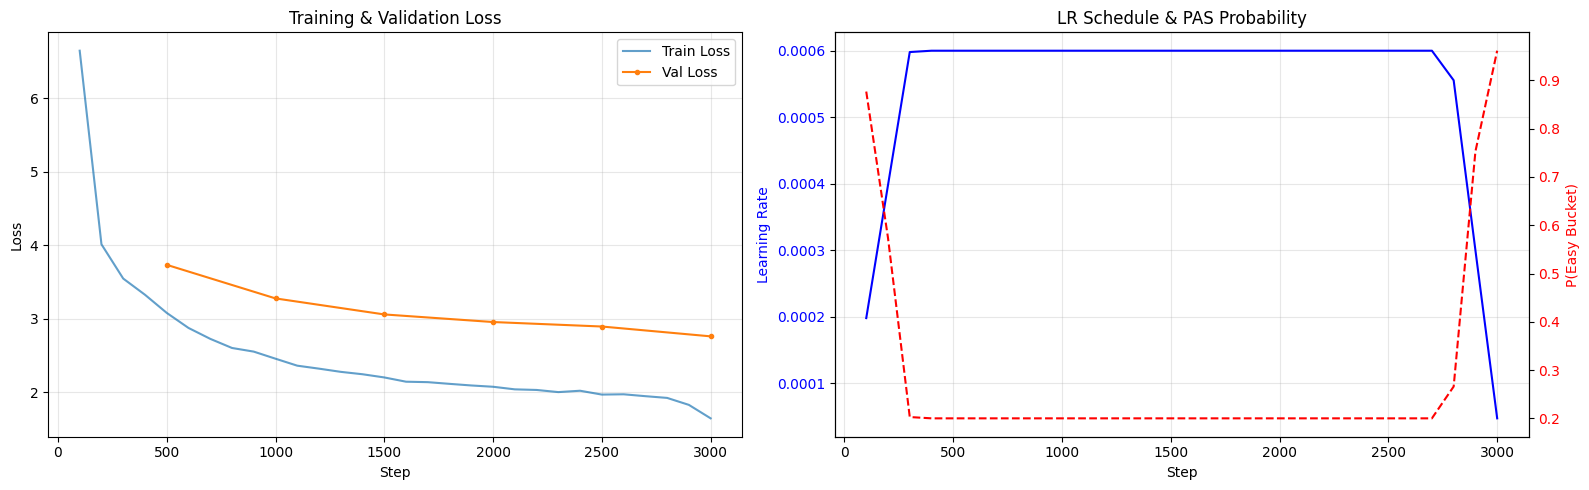

Loss plot saved to: /kaggle/working/cs781_phase1/training_validation_loss.png


In [29]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Loss curves
train_steps_log = [d["step"] for d in train_log]
train_loss_log = [d["loss"] for d in train_log]
val_steps_log = [d["step"] for d in val_log]
val_loss_log = [d["val_loss"] for d in val_log]

ax1.plot(train_steps_log, train_loss_log, label="Train Loss", alpha=0.7)
ax1.plot(val_steps_log, val_loss_log, label="Val Loss", marker="o", markersize=3)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title("Training & Validation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Learning rate + PAS easy-bucket probability
lr_log = [d["lr"] for d in train_log]
pas_easy = [d["pas_probs"][0] for d in train_log]

ax2_lr = ax2
ax2_lr.plot(train_steps_log, lr_log, label="Learning Rate", color="blue")
ax2_lr.set_xlabel("Step")
ax2_lr.set_ylabel("Learning Rate", color="blue")
ax2_lr.tick_params(axis="y", labelcolor="blue")

ax2_pas = ax2_lr.twinx()
ax2_pas.plot(train_steps_log, pas_easy, label="PAS Easy Bucket Prob", color="red", linestyle="--")
ax2_pas.set_ylabel("P(Easy Bucket)", color="red")
ax2_pas.tick_params(axis="y", labelcolor="red")

ax2.set_title("LR Schedule & PAS Probability")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()
print(f"Loss plot saved to: {LOSS_PLOT_PATH}")

## 20. Final Validation Perplexity

In [30]:
# Load best checkpoint
print("Loading best checkpoint for evaluation...")
best_step_loaded, best_loss_loaded = load_checkpoint(
    os.path.join(CHECKPOINT_DIR, "best.pt"), model
)
print(f"Loaded best checkpoint from step {best_step_loaded}, loss {best_loss_loaded:.4f}")

# Full validation evaluation
val_loss, val_ppl = evaluate_val(model, val_blocks, BLOCK_SIZE, device)
print(f"\nFinal Validation Loss: {val_loss:.6f}")
print(f"Final Validation Perplexity: {val_ppl:.4f}")

Loading best checkpoint for evaluation...
Loaded best checkpoint from step 3000, loss 2.7578


Validation:   0%|          | 0/611 [00:00<?, ?it/s]


Final Validation Loss: 2.757783
Final Validation Perplexity: 15.7648


## 21. Save Final Model & Tokenizer

In [31]:
# Save model state dict
torch.save({
    "model_state_dict": model.state_dict(),
    "config": {
        "vocab_size": VOCAB_SIZE,
        "d_model": D_MODEL,
        "n_layers": N_LAYERS,
        "n_heads": N_HEADS,
        "head_dim": HEAD_DIM,
        "d_ff": D_FF,
        "max_seq_len": MAX_SEQ_LEN,
        "rope_base": ROPE_BASE,
        "dropout": DROPOUT,
    },
    "training_info": {
        "total_tokens": tokens_seen,
        "best_val_loss": best_val_loss,
        "best_step": best_step,
    }
}, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))

# Save config as JSON for easy loading
with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w") as f:
    json.dump({
        "vocab_size": VOCAB_SIZE,
        "d_model": D_MODEL,
        "n_layers": N_LAYERS,
        "n_heads": N_HEADS,
        "head_dim": HEAD_DIM,
        "d_ff": D_FF,
        "max_seq_len": MAX_SEQ_LEN,
        "rope_base": ROPE_BASE,
        "dropout": DROPOUT,
        "architecture": "decoder-only-llama-style",
        "components": "RoPE + RMSNorm + SwiGLU + tied_embeddings",
    }, f, indent=2)

# Save tokenizer alongside model
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print(f"Final model saved to: {MODEL_OUTPUT_DIR}")
print(f"Files: {os.listdir(MODEL_OUTPUT_DIR)}")

Final model saved to: /kaggle/working/cs781_phase1/legal-lm-final
Files: ['tokenizer_config.json', 'model.pt', 'config.json', 'tokenizer.json']


## 22. Load Test Prompts

In [32]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print(f"Number of test examples: {len(test_data)}")

# Preview first example
first_key = list(test_data.keys())[0]
first_text = test_data[first_key]["text"]
print(f"\nFirst example ID: {first_key}")
print(f"Prompt preview (first 200 chars): {first_text[:200]}...")
print(f"Prompt word count: {len(first_text.split())}")

Number of test examples: 1000

First example ID: 1
Prompt preview (first 200 chars): The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court...
Prompt word count: 512


## 23. Generation Function

In [33]:
def generate_continuations(prompts, model, tokenizer, device,
                           target_words=128, max_new_tokens=384,
                           temperature=0.7, top_p=0.9, top_k=50,
                           repetition_penalty=1.1, max_input_tokens=None):
    """
    Generate continuations for a list of prompts.
    Returns list of strings, each exactly target_words words.
    
    Processes one prompt at a time to handle variable lengths.
    """
    if max_input_tokens is None:
        max_input_tokens = MAX_SEQ_LEN - max_new_tokens
    
    model.eval()
    results = []
    
    for prompt in tqdm(prompts, desc="Generating continuations", leave=False):
        # Tokenize
        input_ids = tokenizer.encode(prompt, add_special_tokens=False)
        # Truncate if too long
        if len(input_ids) > max_input_tokens:
            input_ids = input_ids[-max_input_tokens:]  # keep the END of prompt (most recent context)
        
        input_tensor = torch.tensor([input_ids], dtype=torch.long, device=device)
        input_len = input_tensor.shape[1]
        
        # Generate
        with torch.no_grad():
            output_ids = model.generate(
                input_tensor,
                max_new_tokens=max_new_tokens,
                temperature=temperature,
                top_p=top_p,
                top_k=top_k,
                repetition_penalty=repetition_penalty,
                eos_token_id=tokenizer.eos_token_id,
            )
        
        # Extract only newly generated tokens
        new_tokens = output_ids[0, input_len:].tolist()
        generated_text = tokenizer.decode(new_tokens, skip_special_tokens=True)
        
        # Truncate to exactly target_words words
        words = generated_text.split()
        words = words[:target_words]
        result = " ".join(words)
        
        # If we got fewer than target_words, that's fine (won't pad with garbage)
        results.append(result)
    
    return results

## 24. Generate Predictions

In [34]:
model.eval()
predictions = {}
GENERATION_BATCH_SIZE = 1  # process one at a time for variable-length prompts

items = list(test_data.items())
total_examples = len(items)
print(f"Generating predictions for {total_examples} test examples...")

gen_start = time.time()

for idx, (example_id, record) in enumerate(tqdm(items, desc="Generating predictions")):
    prompt = record["text"]
    
    continuation = generate_continuations(
        [prompt], model, tokenizer, device,
        target_words=TARGET_GENERATION_WORDS,
        max_new_tokens=MAX_GENERATION_TOKENS,
        temperature=TEMPERATURE,
        top_p=TOP_P,
        top_k=TOP_K,
        repetition_penalty=REPETITION_PENALTY,
    )[0]
    
    predictions[str(example_id)] = {"text": continuation}
    
    if (idx + 1) % 10 == 0 or (idx + 1) == total_examples:
        elapsed = time.time() - gen_start
        eta = elapsed / (idx + 1) * (total_examples - idx - 1)
        tqdm.write(f"  {idx+1}/{total_examples} ({100*(idx+1)/total_examples:.1f}%) "
              f"| Elapsed: {elapsed:.0f}s | ETA: {eta:.0f}s")

gen_time = time.time() - gen_start
print(f"\nGeneration complete in {gen_time:.1f}s ({gen_time/total_examples:.2f}s per example)")

# Sanity check
sample_id = list(predictions.keys())[0]
sample_text = predictions[sample_id]["text"]
print(f"\nSample prediction (ID={sample_id}):")
print(f"  Word count: {len(sample_text.split())}")
print(f"  Text: {sample_text[:300]}...")

Generating predictions for 1000 test examples...


Generating predictions:   0%|          | 0/1000 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

... (1,092 outputs left out)

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating continuations:   0%|          | 0/1 [00:00<?, ?it/s]

  1000/1000 (100.0%) | Elapsed: 21655s | ETA: 0s

Generation complete in 21655.0s (21.66s per example)

Sample prediction (ID=1):
  Word count: 128
  Text: for the party aggrieved to approach the Court and seek relief in that behalf. If the Court finds that there is inordinate delay in approaching the Court, it may cause prejudice to him. The Court shall decide the matter upon due consideration of the material on record and after giving opportunity to ...


## 25. Save prediction.json

In [35]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print(f"prediction.json saved: {PREDICTION_PATH}")
print(f"Number of predictions: {len(predictions)}")

# Verify all test IDs are present
test_ids = set(str(k) for k in test_data.keys())
pred_ids = set(predictions.keys())
assert test_ids == pred_ids, f"ID mismatch! Missing: {test_ids - pred_ids}, Extra: {pred_ids - test_ids}"
print("All test IDs present in predictions.")

prediction.json saved: /kaggle/working/cs781_phase1/prediction.json
Number of predictions: 1000
All test IDs present in predictions.


## 26. Create CodaBench Submission ZIP

In [36]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print(f"Submission ZIP created: {SUBMISSION_ZIP}")
print(f"ZIP size: {os.path.getsize(SUBMISSION_ZIP) / 1024:.1f} KB")

# Verify ZIP contents
with zipfile.ZipFile(SUBMISSION_ZIP, "r") as zipf:
    print(f"ZIP contents: {zipf.namelist()}")
    assert "prediction.json" in zipf.namelist(), "prediction.json not at root of ZIP!"
print("Submission ZIP is valid.")

Submission ZIP created: /kaggle/working/cs781_phase1/submission.zip
ZIP size: 192.5 KB
ZIP contents: ['prediction.json']
Submission ZIP is valid.


## 27. (Optional) Quick Generation Quality Check

In [37]:
# Show a few sample generations for manual inspection
print("=" * 80)
print("SAMPLE GENERATIONS FOR MANUAL INSPECTION")
print("=" * 80)

sample_items = list(test_data.items())[:3]  # first 3

for example_id, record in sample_items:
    prompt = record["text"]
    pred_text = predictions[str(example_id)]["text"]
    
    print(f"\n{'---' * 27}")
    print(f"ID: {example_id}")
    print(f"PROMPT (last 150 words): ...{' '.join(prompt.split()[-150:])}")
    print(f"\nGENERATED ({len(pred_text.split())} words):")
    print(pred_text)
    print()

SAMPLE GENERATIONS FOR MANUAL INSPECTION

---------------------------------------------------------------------------------
ID: 1
PROMPT (last 150 words): ...taken in furtherance thereof and vest in the State free from all encumbrances, the slumbered interested person would be told off the gates of the Court that his grievance should not be entertained when there is inordinate delay in filing the writ petition and when all steps taken in the acquisition proceedings have become final, the Court should be loath to quash the notifications. (Emphasis added) 5 10. Similar view has been reiterated in [State of Rajasthan & Ors. Vs. D.R. Laxmi & Ors.], (1996) 6 SCC 445, wherein this Court has held that even the void proceedings need not be set at naught if the party has not approached the Court within reasonable time, as judicial review is not permissible at a belated stage. This Court held as under: " Delay in challenging the notification was fatal and writ petition entails with dismissal on 

## 28. Training Summary

In [38]:
print("=" * 60)
print("PHASE 1 TRAINING SUMMARY")
print("=" * 60)
print(f"Architecture: Decoder-only Transformer (RoPE + RMSNorm + SwiGLU)")
print(f"Parameters: {unique_params/1e6:.1f}M")
print(f"Layers: {N_LAYERS}, Heads: {N_HEADS}, d_model: {D_MODEL}, d_ff: {D_FF}")
print(f"Context length: {MAX_SEQ_LEN}")
print(f"Tokenizer: Custom BPE (vocab={VOCAB_SIZE})")
print(f"Total tokens seen: {tokens_seen:,}")
print(f"Training time: {total_time/3600:.2f} hours")
print(f"Training speed: {tokens_seen/total_time:,.0f} tokens/sec")
print(f"Best val loss: {best_val_loss:.4f} (step {best_step})")
print(f"Best val perplexity: {math.exp(min(best_val_loss, 20)):.2f}")
print(f"Peak LR: {PEAK_LR}")
print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE:,} tokens")
print(f"PAS: lambda={PAS_LAMBDA}, target_weights={PAS_TARGET_WEIGHTS}")
print(f"Generation: temp={TEMPERATURE}, top_p={TOP_P}, top_k={TOP_K}, rep_pen={REPETITION_PENALTY}")
print(f"\nFiles:")
print(f"  Model: {MODEL_OUTPUT_DIR}")
print(f"  Predictions: {PREDICTION_PATH}")
print(f"  Submission: {SUBMISSION_ZIP}")
print(f"  Loss plot: {LOSS_PLOT_PATH}")
print("=" * 60)

PHASE 1 TRAINING SUMMARY
Architecture: Decoder-only Transformer (RoPE + RMSNorm + SwiGLU)
Parameters: 85.0M
Layers: 12, Heads: 12, d_model: 768, d_ff: 2048
Context length: 1024
Tokenizer: Custom BPE (vocab=32000)
Total tokens seen: 199,950,336
Training time: 5.70 hours
Training speed: 9,736 tokens/sec
Best val loss: 2.7578 (step 3000)
Best val perplexity: 15.76
Peak LR: 0.0006
Effective batch size: 65,536 tokens
PAS: lambda=5.0, target_weights=[0.2, 0.4, 0.4]
Generation: temp=0.7, top_p=0.9, top_k=50, rep_pen=1.1

Files:
  Model: /kaggle/working/cs781_phase1/legal-lm-final
  Predictions: /kaggle/working/cs781_phase1/prediction.json
  Submission: /kaggle/working/cs781_phase1/submission.zip
  Loss plot: /kaggle/working/cs781_phase1/training_validation_loss.png
